# 04 · Posterior on the real data

What does the posterior say about the location, scale and tail heaviness of US stock-market returns, and how sure can we be that our numbers are right?

| Reads | Produces | Running time |
|---|---|---|
| `data/returns.csv`<br>`tools.py` | `results/draws_student_t.npy`, `results/draws_gaussian.npy` (for notebooks 05 and 06)<br>`../report/tables/posterior.tex`, `../report/figures/posterior.pdf` (report, Section 6.1 and appendix)<br>`../report/figures/posterior_diagnostics.pdf`, `../report/figures/running_means.pdf` (report, appendix) | about 30 seconds |

01 Data → 02 Model and sampler → 03 Validation → **04 Posterior** → 05 Risk → 06 Checks

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tools import (BURN_IN, COLOR_DATA, COLOR_GAUSS, COLOR_T, PRIOR, convergence_checks, find_map,
                   independence_sampler, log_posterior, log_posterior_gauss, plot_diagnostics,
                   run_chains, save_figure, save_table, set_style, summarize, to_theta)

SEED = 2026
rng = np.random.default_rng(SEED)
SECOND_SEED = 2027  # for the rerun of Section 3.2
N_SIMULATED = 1_000  # simulated data sets in Section 2.3

# The daily log-returns of notebook 01, in decimals
y = pd.read_csv("data/returns.csv")["y"].to_numpy()
n = len(y)
set_style()

## 1. Fitting the Student-t model

We run on the real returns exactly the recipe validated in notebook 03: the MAP and the Laplace covariance, 3 pilot rounds, then 4 chains of 20,000 iterations from dispersed starting points, of which the first 2,000 are discarded.

In [2]:
# Fit the Student-t model to the real returns
def target(phi):
    """Log posterior of the Student-t model given the real returns."""
    return log_posterior(phi, y)

start = [np.median(y), np.log(y.std()), 0.0]  # the MAP search starts at nu = 3
chains, accept = run_chains(target, start, rng)
theta_draws = to_theta(chains)  # every iteration, burn-in included (for the figure)
kept = theta_draws[:, BURN_IN:]  # the draws we use: 4 chains x 18,000
mu, sigma, nu = kept[..., 0], kept[..., 1], kept[..., 2]

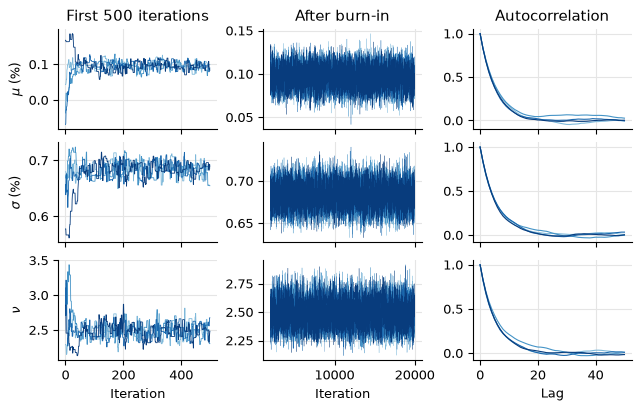

In [3]:
# Traces and autocorrelations of the 4 chains (mu and sigma in %)
fig = plot_diagnostics(theta_draws * [100, 100, 1], [r"$\mu$ (%)", r"$\sigma$ (%)", r"$\nu$"])
save_figure(fig, "posterior_diagnostics.pdf")
plt.show()

## 2. The posterior

Each posterior summary is a Monte Carlo estimate from the $4 \times 18{,}000$ draws. Besides the three parameters, we report the **implied standard deviation** of daily returns, $\sigma\sqrt{\nu/(\nu-2)}$, a function of $\theta$ whose posterior we get by computing it draw by draw.

In [4]:
# Posterior summaries of the Student-t model (returns-scale quantities in %), and convergence checks
sd_implied = sigma * np.sqrt(nu / (nu - 2))
student_t = {"mu (%)": 100 * mu, "sigma (%)": 100 * sigma, "nu": nu, "implied sd (%)": 100 * sd_implied}
posterior_t = pd.DataFrame([summarize(x) for x in student_t.values()], index=list(student_t))

print("acceptance rates:", accept.round(3))
for check, passed in convergence_checks(posterior_t, accept).items():
    print("PASS" if passed else "FAIL", check)
posterior_t

acceptance rates: [0.308 0.307 0.312 0.31 ]
PASS split-R-hat < 1.01 for every quantity
PASS ESS >= 1,000 for every quantity
PASS acceptance rate in [0.2, 0.5] for every chain


,mean,sd,2.5%,97.5%,R-hat,ESS,MCSE
mu (%),0.096495,0.012026,0.073069,0.120130,1.000211,6321.355730,0.000151
sigma (%),0.683232,0.013856,0.656278,0.710852,1.001160,6529.237800,0.000171
nu,2.480516,0.110005,2.273657,2.703903,1.000979,6531.269751,0.001361
implied sd (%),1.578996,0.142342,1.370364,1.920988,1.000756,5969.846822,0.001842


### 2.1 Probabilities of events

A Student-t with $\nu$ degrees of freedom has finite moments only up to order $\nu$: the skewness needs $\nu > 3$ and the kurtosis $\nu > 4$. The posterior probability of an event is the fraction of draws in which it happens. Some of these probabilities are very close to 1, so we print counts of draws.

> **[COURSE]** Probability of an event as a posterior expectation, $\Pr(A \mid y) = \mathbb{E}[\mathbf 1\{\theta \in A\} \mid y]$: Ch. 1, Sec. 1.2.2, Definition 1.4 (p. 16).

In [5]:
# Probabilities of events, as counts of draws
n_draws = nu.size
print(f"nu < 4 (infinite kurtosis):  {np.sum(nu < 4):,} of {n_draws:,} draws")
print(f"nu < 3 (infinite skewness):  {np.sum(nu < 3):,} of {n_draws:,} draws")
print(f"2.5% quantile of nu: {np.quantile(nu, 0.025):.3f}, against the lower bound nu > {PRIOR['nu_min']:g}")

nu < 4 (infinite kurtosis):  72,000 of 72,000 draws
nu < 3 (infinite skewness):  72,000 of 72,000 draws
2.5% quantile of nu: 2.274, against the lower bound nu > 2


### 2.2 Does the prior matter? The maximum-likelihood fit

With weakly informative priors and 5,031 days, the posterior means should be close to the maximum-likelihood estimates, computed here with SciPy (only as a check: SciPy's `stats.t.fit` is not part of our method).

In [6]:
# Posterior means against SciPy's maximum-likelihood fit
nu_mle, mu_mle, sigma_mle = stats.t.fit(y)
mle_check = pd.DataFrame({"posterior mean": [100 * mu.mean(), 100 * sigma.mean(), nu.mean()],
                          "maximum likelihood": [100 * mu_mle, 100 * sigma_mle, nu_mle]},
                         index=["mu (%)", "sigma (%)", "nu"])
mle_check["difference (posterior sd)"] = ((mle_check["posterior mean"] - mle_check["maximum likelihood"])
                                          / posterior_t["sd"].iloc[:3].to_numpy())
mle_check

,posterior mean,maximum likelihood,difference (posterior sd)
mu (%),0.096495,0.097893,-0.116198
sigma (%),0.683232,0.681942,0.093150
nu,2.480516,2.470240,0.093422


### 2.3 Two comparisons with the data

The Student-t posterior differs from the raw data in two ways that need an explanation:
- its **implied standard deviation** is larger than the sample standard deviation;
- its **location** $\mu$ is larger than the sample mean.

In [7]:
# The model's sd and location against the data's
print(f"sd:       implied by the model {100 * sd_implied.mean():.3f}% "
      f"[{100 * np.quantile(sd_implied, 0.025):.3f}, {100 * np.quantile(sd_implied, 0.975):.3f}], "
      f"sample sd {100 * y.std(ddof=1):.3f}%")
print(f"location: Student-t mu {100 * mu.mean():.3f}%, sample mean {100 * y.mean():.3f}%, "
      f"sample median {100 * np.median(y):.3f}%")

sd:       implied by the model 1.579% [1.370, 1.921], sample sd 1.246%
location: Student-t mu 0.096%, sample mean 0.042%, sample median 0.080%


With $\nu$ close to 2.5, the variance is finite but the fourth moment is not, so the sample standard deviation converges very slowly and is erratic from one sample to the next: it depends on whether a few enormous days happen to be in the sample. Is a sample sd below the true sd then the typical situation? We simulate 1,000 data sets of $n$ days from the model, with $\theta$ at its posterior mean, and compare their sample standard deviations with the true one.

> **[COURSE]** When the CLT fails: Ch. 3, Sec. 3.3.3, Example 3.3 and Remark 3.1 (pp. 42–43).
> With heavy tails, averages still converge (law of large numbers) but slowly and irregularly, so their standard errors cannot be trusted.

In [8]:
# Sample sd of N_SIMULATED data sets of n days simulated from the model at the posterior mean
mu_hat, sigma_hat, nu_hat = mu.mean(), sigma.mean(), nu.mean()
true_sd = sigma_hat * np.sqrt(nu_hat / (nu_hat - 2))
sample_sds = np.empty(N_SIMULATED)
for k in range(N_SIMULATED):
    y_k = mu_hat + sigma_hat * rng.standard_t(nu_hat, n)
    sample_sds[k] = y_k.std(ddof=1)

ratio = sample_sds / true_sd
print(f"true sd of the model: {100 * true_sd:.3f}%")
print(f"sample sd / true sd over {N_SIMULATED:,} simulated data sets: median {np.median(ratio):.2f}, "
      f"5%-95% range [{np.quantile(ratio, 0.05):.2f}, {np.quantile(ratio, 0.95):.2f}]")
print(f"share of data sets whose sample sd falls below the true sd: {np.mean(ratio < 1):.0%}")
our_ratio = y.std(ddof=1) / true_sd
print(f"our data: sample sd / true sd = {our_ratio:.2f}; "
      f"simulated data sets that fall at least this short: {np.mean(ratio <= our_ratio):.1%}")

true sd of the model: 1.552%


sample sd / true sd over 1,000 simulated data sets: median 0.91, 5%-95% range [0.83, 1.17]
share of data sets whose sample sd falls below the true sd: 81%
our data: sample sd / true sd = 0.80; simulated data sets that fall at least this short: 1.7%


**What we see.**
- **The tails are very heavy.** Every one of the 72,000 draws has $\nu < 3$: under the model, the skewness and the kurtosis of daily returns are infinite. The 95% interval of $\nu$ stays clear of the bound $\nu > 2$, so the finite-variance assumption is not what drives the result.
- **The priors barely matter:** the posterior means are within a fraction of a posterior standard deviation of the maximum-likelihood estimates. Notebook 06 confirms it by changing the priors.
- **The implied sd is 27% larger than the sample sd. The direction is expected, the size less so.** With $\nu$ near 2.5, the sample sd of $n$ days usually falls short of the true sd, because the days that would reveal the full spread are rare: it does so in about four simulated data sets out of five, typically by about 9%. Our data fall shorter than that, by 20%, which fewer than 2 simulated data sets in 100 do. So the fitted model expects even more extreme days than our data contain: its far tail may be somewhat too heavy, which would make it conservative at the most extreme levels. Notebook 06 checks the tails directly with posterior predictive checks.
- **The location is closer to the median than to the mean.** The Student-t centre $\mu$ describes a typical day; a few very large losses pull the sample mean down. This asymmetry is ignored by our symmetric model, a limitation we keep in mind.

## 3. Can we trust these numbers?

The convergence checks above passed. Following the checklist of App. B.5 for any Monte Carlo number, we add three checks on this posterior:
1. the **running means** of the parameters should settle as the chains grow;
2. a **second seed** should give the same posterior means within a few Monte Carlo standard errors;
3. a **second sampler**, the independence sampler of notebook 03, which moves in a completely different way, should give the same posterior.

> **[COURSE]** Checklist before reporting a Monte Carlo number: App. B.5, items 2 and 3 (p. 87). Two different algorithms that agree: Ch. 6, Example 6.2 (p. 69). Independence sampler: Sec. 6.3 (p. 70).

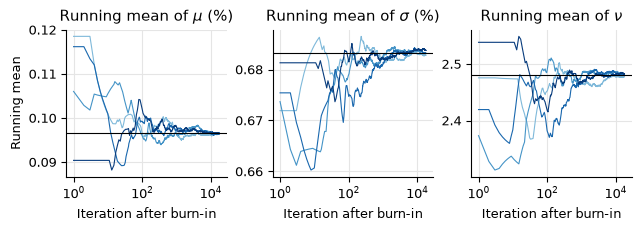

In [9]:
# Running means of mu, sigma and nu along each chain (after burn-in), on a logarithmic iteration axis
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.2))
shades = plt.cm.Blues(np.linspace(0.45, 0.95, 4))
iterations = np.arange(1, kept.shape[1] + 1)
for i, (ax, label, scale) in enumerate(zip(axes, [r"$\mu$ (%)", r"$\sigma$ (%)", r"$\nu$"], [100, 100, 1])):
    for c in range(4):
        running_mean = np.cumsum(scale * kept[c, :, i]) / iterations
        ax.plot(iterations, running_mean, color=shades[c], linewidth=0.8)
    ax.axhline(scale * kept[..., i].mean(), color="black", linewidth=0.8)
    ax.set(xscale="log", xlabel="Iteration after burn-in", title=f"Running mean of {label}")
axes[0].set_ylabel("Running mean")
save_figure(fig, "running_means.pdf")
plt.show()

In [10]:
# A second fit with another seed: the posterior means should agree within a few MCSE
rng_2 = np.random.default_rng(SECOND_SEED)
chains_2, accept_2 = run_chains(target, start, rng_2)
kept_2 = to_theta(chains_2[:, BURN_IN:])

rows = []
for i, (name, scale) in enumerate([("mu (%)", 100), ("sigma (%)", 100), ("nu", 1)]):
    first = summarize(scale * kept[..., i])
    second = summarize(scale * kept_2[..., i])
    combined_mcse = np.sqrt(first["MCSE"] ** 2 + second["MCSE"] ** 2)
    rows.append([name, first["mean"], second["mean"], (first["mean"] - second["mean"]) / combined_mcse])
seed_check = pd.DataFrame(rows, columns=["quantity", f"seed {SEED}", f"seed {SECOND_SEED}",
                                         "difference (in MCSE)"]).set_index("quantity")
seed_check

,seed 2026,seed 2027,difference (in MCSE)
quantity,,,
mu (%),0.096495,0.096601,-0.507518
sigma (%),0.683232,0.683150,0.340510
nu,2.480516,2.481446,-0.479314


In [11]:
# A second sampler: one chain of the independence sampler, from the MAP with the Laplace covariance
mode, laplace = find_map(target, start)
draws_ind, accept_ind = independence_sampler(target, mode, laplace, 20_000, rng)
kept_ind = to_theta(draws_ind[BURN_IN:])
print(f"independence sampler: acceptance rate {accept_ind:.2f}")

rows = []
for i, (name, scale) in enumerate([("mu (%)", 100), ("sigma (%)", 100), ("nu", 1)]):
    rw = scale * kept[..., i]
    ind = scale * kept_ind[:, i]
    rows.append([name, rw.mean(), ind.mean(), np.quantile(rw, 0.025), np.quantile(ind, 0.025),
                 np.quantile(rw, 0.975), np.quantile(ind, 0.975)])
sampler_check = pd.DataFrame(rows, columns=["quantity", "mean: random walk", "mean: independence",
                                            "2.5%: random walk", "2.5%: independence",
                                            "97.5%: random walk", "97.5%: independence"])
sampler_check.set_index("quantity")

independence sampler: acceptance rate 0.75


,mean: random walk,mean: independence,2.5%: random walk,2.5%: independence,97.5%: random walk,97.5%: independence
quantity,,,,,,
mu (%),0.096495,0.096240,0.073069,0.072745,0.120130,0.119503
sigma (%),0.683232,0.683026,0.656278,0.656555,0.710852,0.710750
nu,2.480516,2.479564,2.273657,2.274500,2.703903,2.704068


**What we see.** The running means settle within a few thousand iterations, all four chains on the same value. The second seed reproduces the posterior means within about half a Monte Carlo standard error, and the independence sampler, which proposes from a fixed global approximation instead of local steps, reaches the same means and the same 95% intervals. Our posterior is not an artefact of one chain, one seed or one algorithm.

## 4. The Gaussian benchmark

To measure what the heavy tails change, we also fit a **Gaussian** model, $y_t \overset{\text{iid}}{\sim} \mathcal N(\mu, s^2)$, with the same priors as the Student-t's location and scale ($\mu \sim \mathcal N(0, 0.001^2)$, $s \sim$ HalfNormal$(0.02)$), so that the two models differ only in their tails. We sample $(\mu, \log s)$ with the same recipe (`log_posterior_gauss` in `tools.py`, Jacobian included).

In [12]:
# Fit the Gaussian model with the same recipe
def target_gauss(phi):
    """Log posterior of the Gaussian model given the real returns."""
    return log_posterior_gauss(phi, y)

chains_g, accept_g = run_chains(target_gauss, [y.mean(), np.log(y.std())], rng)
mu_g = chains_g[:, BURN_IN:, 0]
s_g = np.exp(chains_g[:, BURN_IN:, 1])

gaussian = {"mu (%)": 100 * mu_g, "s (%)": 100 * s_g}
posterior_g = pd.DataFrame([summarize(x) for x in gaussian.values()], index=list(gaussian))
print("acceptance rates:", accept_g.round(3))
for check, passed in convergence_checks(posterior_g, accept_g).items():
    print("PASS" if passed else "FAIL", check)
posterior_g

acceptance rates: [0.354 0.352 0.354 0.349]
PASS split-R-hat < 1.01 for every quantity
PASS ESS >= 1,000 for every quantity
PASS acceptance rate in [0.2, 0.5] for every chain


,mean,sd,2.5%,97.5%,R-hat,ESS,MCSE
mu (%),0.040465,0.017446,0.006407,0.074606,1.000884,8855.612889,0.000185
s (%),1.246172,0.012561,1.221634,1.270811,1.000294,9563.023774,0.000128


**What we see.** The Gaussian fit converges as well. Its location is the sample mean and its standard deviation the sample standard deviation, both pinned down very precisely: a Gaussian has no tail parameter to be uncertain about, so it reports a narrow, confident answer about the spread. Notebook 05 shows what this confidence costs in the tails.

## 5. Table, figure and draws for the next notebooks

In [13]:
# Table for the report: both models (returns-scale quantities in %)
labels = {"mu (%)": r"$\mu$ (%)", "sigma (%)": r"$\sigma$ (%)", "nu": r"$\nu$",
          "implied sd (%)": "implied sd (%)", "s (%)": r"$s$ (%)"}
rows = {}
for model, table in [("Student-t", posterior_t), ("Gaussian", posterior_g)]:
    for name, s in table.iterrows():
        d = 2 if name == "nu" else 3  # decimals shown
        rows[f"{model}: {labels[name]}"] = {"Mean": f"{s['mean']:.{d}f}", "Sd": f"{s['sd']:.{d}f}",
                                            "95% interval": f"[{s['2.5%']:.{d}f}, {s['97.5%']:.{d}f}]",
                                            r"$\hat R$": f"{s['R-hat']:.4f}", "ESS": f"{s['ESS']:,.0f}",
                                            "MCSE": f"{s['MCSE']:.2g}"}
posterior_report = pd.DataFrame.from_dict(rows, orient="index")
posterior_report.index.name = "Model: quantity"
save_table(posterior_report, "posterior.tex")
posterior_report

,Mean,Sd,95% interval,$\hat R$,ESS,MCSE
Model: quantity,,,,,,
Student-t: $\mu$ (%),0.096,0.012,"[0.073, 0.120]",1.0002,"6,321",0.00015
Student-t: $\sigma$ (%),0.683,0.014,"[0.656, 0.711]",1.0012,"6,529",0.00017
Student-t: $\nu$,2.48,0.11,"[2.27, 2.70]",1.0010,"6,531",0.0014
Student-t: implied sd (%),1.579,0.142,"[1.370, 1.921]",1.0008,"5,970",0.0018
Gaussian: $\mu$ (%),0.040,0.017,"[0.006, 0.075]",1.0009,"8,856",0.00019
Gaussian: $s$ (%),1.246,0.013,"[1.222, 1.271]",1.0003,"9,563",0.00013


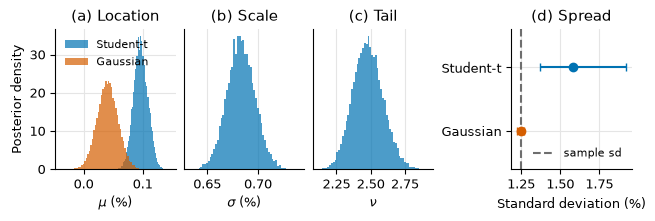

In [14]:
# Figure: posteriors of mu (both models), sigma and nu, and the sd of each model against the sample sd
fig, axes = plt.subplots(1, 4, figsize=(6.3, 2.1))

axes[0].hist(100 * mu.ravel(), bins=60, density=True, color=COLOR_T, alpha=0.7, label="Student-t")
axes[0].hist(100 * mu_g.ravel(), bins=60, density=True, color=COLOR_GAUSS, alpha=0.7, label="Gaussian")
axes[0].set(xlabel=r"$\mu$ (%)", ylabel="Posterior density", title="(a) Location")
axes[0].legend(loc="upper left")
axes[1].hist(100 * sigma.ravel(), bins=60, density=True, color=COLOR_T, alpha=0.7)
axes[1].set(xlabel=r"$\sigma$ (%)", title="(b) Scale")
axes[2].hist(nu.ravel(), bins=60, density=True, color=COLOR_T, alpha=0.7)
axes[2].set(xlabel=r"$\nu$", title="(c) Tail")

# (d) Each model's standard deviation: posterior mean and 95% interval, against the sample sd
for row, (values, color) in enumerate([(100 * s_g, COLOR_GAUSS), (100 * sd_implied, COLOR_T)]):
    low, high = np.quantile(values, [0.025, 0.975])
    axes[3].errorbar(values.mean(), row, xerr=[[values.mean() - low], [high - values.mean()]],
                     fmt="o", color=color, capsize=3)
axes[3].axvline(100 * y.std(ddof=1), color=COLOR_DATA, linestyle="--", label="sample sd")
axes[3].set(yticks=[0, 1], yticklabels=["Gaussian", "Student-t"], ylim=(-0.6, 1.6),
            xlabel="Standard deviation (%)", title="(d) Spread")
axes[3].legend(loc="lower right")
for ax in axes[1:3]:
    ax.set_yticks([])
save_figure(fig, "posterior.pdf")
plt.show()

In [15]:
# Save the draws after burn-in for notebooks 05 and 06: (mu, sigma, nu) and, for the Gaussian, (mu, s)
Path("results").mkdir(exist_ok=True)
np.save("results/draws_student_t.npy", kept)
np.save("results/draws_gaussian.npy", np.stack([mu_g, s_g], axis=-1))
print("saved: results/draws_student_t.npy", kept.shape, "and results/draws_gaussian.npy", mu_g.shape + (2,))

saved: results/draws_student_t.npy (4, 18000, 3) and results/draws_gaussian.npy (4, 18000, 2)


## 6. What we found

In [16]:
# Numbers quoted in the report
for name, s in posterior_t.iterrows():
    print(f"Student-t {name:>15}: {s['mean']:.3f} [{s['2.5%']:.3f}, {s['97.5%']:.3f}]")
for name, s in posterior_g.iterrows():
    print(f"Gaussian  {name:>15}: {s['mean']:.3f} [{s['2.5%']:.3f}, {s['97.5%']:.3f}]")
print(f"Convergence: R-hat <= {max(posterior_t['R-hat'].max(), posterior_g['R-hat'].max()):.4f}, "
      f"ESS >= {min(posterior_t['ESS'].min(), posterior_g['ESS'].min()):,.0f}, "
      f"acceptance {accept.min():.2f}-{accept.max():.2f} (Student-t), "
      f"{accept_g.min():.2f}-{accept_g.max():.2f} (Gaussian)")
print(f"nu < 4: {np.sum(nu < 4):,} of {n_draws:,} draws; nu < 3: {np.sum(nu < 3):,} of {n_draws:,}")
print(f"Maximum likelihood: nu = {nu_mle:.2f}, mu = {100 * mu_mle:.3f}%, sigma = {100 * sigma_mle:.3f}%")
print(f"Implied sd vs sample sd: +{100 * (sd_implied.mean() / y.std(ddof=1) - 1):.0f}%; "
      f"simulated data sets with sample sd below the true sd: {np.mean(ratio < 1):.0%} "
      f"(median ratio {np.median(ratio):.2f}); at least as short as ours ({our_ratio:.2f}): "
      f"{np.mean(ratio <= our_ratio):.1%}")
print(f"Second seed: largest difference {seed_check['difference (in MCSE)'].abs().max():.1f} MCSE; "
      f"independence sampler acceptance {accept_ind:.2f}")

Student-t          mu (%): 0.096 [0.073, 0.120]
Student-t       sigma (%): 0.683 [0.656, 0.711]
Student-t              nu: 2.481 [2.274, 2.704]
Student-t  implied sd (%): 1.579 [1.370, 1.921]
Gaussian           mu (%): 0.040 [0.006, 0.075]
Gaussian            s (%): 1.246 [1.222, 1.271]
Convergence: R-hat <= 1.0012, ESS >= 5,970, acceptance 0.31-0.31 (Student-t), 0.35-0.35 (Gaussian)
nu < 4: 72,000 of 72,000 draws; nu < 3: 72,000 of 72,000
Maximum likelihood: nu = 2.47, mu = 0.098%, sigma = 0.682%
Implied sd vs sample sd: +27%; simulated data sets with sample sd below the true sd: 81% (median ratio 0.91); at least as short as ours (0.80): 1.7%
Second seed: largest difference 0.5 MCSE; independence sampler acceptance 0.75


- **Very heavy tails:** $\nu$ is about 2.5, with a 95% interval well below 3: the kurtosis of daily returns is infinite under the model, and the variance only just finite.
- **The data, not the priors, drive the posterior:** it matches the maximum-likelihood fit.
- **The numbers can be trusted:** every convergence target passes, the running means settle, and a second seed and a second sampler give the same posterior.
- **The Gaussian is confident and narrow:** its sd equals the sample sd, which, with tails this heavy, typically understates the true spread.
- **A point to check:** our sample sd falls further below the model's sd than in almost all data sets simulated from the fit, a hint that the model's far tail is somewhat too heavy (notebook 06).

**Next:** `05_risk.ipynb` turns both posteriors into the one-day VaR and ES, and compares plain Monte Carlo with importance sampling for the rare losses.